# DiaGraMo — Phase 3 recovery và Phase 4 lite

Notebook chỉ đọc artifacts. Cấu hình khóa trước outer evaluation, một seed42 và sáu folds gốc. Phase 3 full SSL và nghiên cứu đầy đủ vẫn chưa hoàn tất. Các dòng partial OOF chỉ so sánh trên đúng participants đã có Raw predictions. Mọi kết quả là exploratory vì cohort đã được nghiên cứu nhiều lần.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'results').exists(): ROOT = ROOT.parent
OUT = ROOT / 'results/raw_temporal_v2'
LITE = OUT / 'phase4_lite'
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
def table(name):
    path = LITE / name
    if path.exists(): display(pd.read_csv(path))
    else: display(Markdown('Chưa có artifact: `' + name + '`'))
display(pd.DataFrame([json.loads((LITE / 'status.json').read_text(encoding='utf-8'))]))

,lite_validation_complete,primary_validation_complete,research_complete,status,primary_folds_completed,secondary_folds_completed,phase3_complete,full_phase4_launched,exploratory,checkpoint_checks_passed
0,False,True,False,lite_incomplete_resumable,6,2,False,False,True,True


## CUDA và epoch SSL nhỏ
Thời gian measured khác với ước lượng extrapolation. Reconstruction pilot không chứng minh giá trị downstream.

In [2]:
for name in ['cuda_smoke.json', 'pilot_result.json']:
    path = OUT / 'phase3_recovery' / name
    if path.exists(): display(pd.DataFrame([json.loads(path.read_text(encoding='utf-8'))]))

,complete,device,strict_deterministic,committed_fix_sha256,normalizer_fit_ids,used_ids,excluded_outer_test_ids,records,setup_and_smoke_seconds
0,True,Quadro T1000,True,68a01f20ec3efa77139a7bab95e67c332efaff09c2d930...,"[BR10301, BR10305, BR10404, BR2402, BR2404, BR...",[HK12403],"[BR10302, BR10403, BR10406, BR2403, BR2408, BR...","[{'encoder': 'original', 'windows': 64, 'finit...",11.650355


,pilot_complete,phase3_complete,fit_ids,normalizer_fit_ids,eligible_windows,epochs_completed,optimizer_updates,training_seconds,forward_only_seconds,windows_per_second,mean_masked_mse,gradient_norm,peak_gpu_allocated_mib,peak_gpu_reserved_mib,setup_and_smoke_seconds,full_train_windows,full_validation_windows,estimated_full_train_epoch_seconds,estimated_validation_forward_seconds,estimated_two_seed_pretraining_upper_seconds,estimated_full_phase3_seconds,estimate_method,configured_full_phase3_budget_seconds,full_suite_estimate_within_budget,full_ssl_launched,reason,small_epoch_scope,checkpoint,checkpoint_sha256
0,True,False,"[BR8416, VV10404, RK06304, HK12403, JI05305, H...","[BR10301, BR10305, BR10404, BR2402, BR2404, BR...",11432,1,1,1.219256,0.219249,9376.209754,0.85907,0.488802,205.583496,340.0,11.650355,192880,97171,20.571212,1.863599,538.435468,3739.487523,"Window throughput scaling, 1.5 safety factor; ...",1800,False,False,Recovery pilot only; prioritize fixed-recipe h...,"Eight development-Train participants, all elig...",data/derived/raw_temporal_v2/phase3_recovery/p...,4f519305e644ca512b843e37cc66c84099737f5c201aab...


## Bảng số OOF — Raw, Kinematic và 50/50
Kinematic trong từng candidate được giới hạn đúng cùng IDs/folds. Chỉ full258 người khi đủ sáu folds.

In [3]:
table('paired_comparison.csv')
table('fold_metrics.csv')

,candidate,method,participants,completed_folds,all_six_folds_complete,accuracy,f1_macro,auc,pr_auc,balanced_accuracy,sensitivity,specificity,brier,fold_accuracy_mean,fold_accuracy_std,fold_f1_macro_mean,fold_f1_macro_std,fold_auc_mean,fold_auc_std,fold_balanced_accuracy_mean,fold_balanced_accuracy_std,fold_specificity_mean,fold_specificity_std
0,duration,raw,258,6,True,0.759690,0.757930,0.822986,0.832199,0.759380,0.762238,0.756522,0.187360,0.759690,0.065227,0.756407,0.066391,0.833658,0.044991,0.760658,0.066371,0.758333,0.128063
1,duration,kinematic,258,6,True,0.848837,0.847163,0.906902,0.926033,0.847461,0.860140,0.834783,0.122450,0.848837,0.032056,0.847047,0.032387,0.904027,0.031284,0.847276,0.032343,0.834649,0.040097
2,duration,fixed_average_50_50,258,6,True,0.837209,0.835539,0.899240,0.907016,0.836120,0.846154,0.826087,0.126748,0.837209,0.041601,0.835463,0.041903,0.901862,0.036074,0.836535,0.041889,0.826754,0.060249
3,stroke_transformer,raw,86,2,False,0.790698,0.788871,0.881069,0.906485,0.788871,0.808511,0.769231,0.148954,0.790698,0.000000,0.786945,0.005306,0.887672,0.037904,0.787085,0.010578,0.767105,0.117231
4,stroke_transformer,kinematic,86,2,False,0.848837,0.847829,0.933988,0.952589,0.848609,0.851064,0.846154,0.106476,0.848837,0.016444,0.847705,0.015342,0.928089,0.045873,0.848298,0.014502,0.846053,0.005582
5,stroke_transformer,fixed_average_50_50,86,2,False,0.906977,0.905702,0.956356,0.967107,0.903983,0.936170,0.871795,0.091515,0.906977,0.032889,0.905600,0.031298,0.958619,0.033710,0.902918,0.025647,0.871053,0.040938


,candidate,method,fold,participants,accuracy,f1_macro,auc,pr_auc,balanced_accuracy,sensitivity,specificity,brier
0,duration,raw,0,43,0.720930,0.708145,0.778261,0.838854,0.709783,0.869565,0.550000,0.236958
1,duration,raw,1,43,0.837209,0.835788,0.864035,0.820000,0.837719,0.833333,0.842105,0.140832
2,duration,raw,2,43,0.790698,0.790244,0.859649,0.874909,0.796053,0.750000,0.842105,0.163978
3,duration,raw,3,43,0.790698,0.786542,0.872807,0.883544,0.785088,0.833333,0.736842,0.164800
4,duration,raw,4,43,0.651163,0.650407,0.774123,0.833674,0.654605,0.625000,0.684211,0.246574
5,duration,raw,5,43,0.767442,0.767316,0.853070,0.895033,0.780702,0.666667,0.894737,0.171020
6,duration,kinematic,0,43,0.837209,0.836856,0.895652,0.928270,0.838043,0.826087,0.850000,0.132145
7,duration,kinematic,1,43,0.860465,0.858553,0.960526,0.970957,0.858553,0.875000,0.842105,0.080807
8,duration,kinematic,2,43,0.837209,0.835788,0.901316,0.932042,0.837719,0.833333,0.842105,0.130283
9,duration,kinematic,3,43,0.906977,0.905702,0.899123,0.918934,0.905702,0.916667,0.894737,0.112100


## Paired error overlap và bootstrap
Corrected cases riêng lẻ không chứng minh complementary value. Bootstrap conditional trên models đã fit.

In [4]:
table('error_overlap.csv')
table('paired_deltas.csv')

,candidate,participants,both_correct,kin_only,raw_only,both_wrong,probability_correlation
0,duration,258,179,40,17,22,0.627886
1,stroke_transformer,86,57,16,11,2,0.555547


,candidate,method,reference,metric,participants,delta,lower95,upper95,bootstrap_replicates
0,duration,raw,kinematic_same_participants,f1_macro,258,-0.089234,-0.145229,-0.035529,500
1,duration,raw,kinematic_same_participants,auc,258,-0.083916,-0.128884,-0.037583,500
2,duration,raw,kinematic_same_participants,balanced_accuracy,258,-0.088081,-0.143805,-0.033797,500
3,duration,raw,kinematic_same_participants,specificity,258,-0.078261,-0.163428,0.000000,500
4,duration,fixed_average_50_50,kinematic_same_participants,f1_macro,258,-0.011624,-0.048900,0.027162,500
5,duration,fixed_average_50_50,kinematic_same_participants,auc,258,-0.007662,-0.028089,0.013741,500
6,duration,fixed_average_50_50,kinematic_same_participants,balanced_accuracy,258,-0.011341,-0.048368,0.028050,500
7,duration,fixed_average_50_50,kinematic_same_participants,specificity,258,-0.008696,-0.069443,0.050445,500
8,stroke_transformer,raw,kinematic_same_participants,f1_macro,86,-0.058958,-0.168935,0.064246,500
9,stroke_transformer,raw,kinematic_same_participants,auc,86,-0.052919,-0.135654,0.023120,500


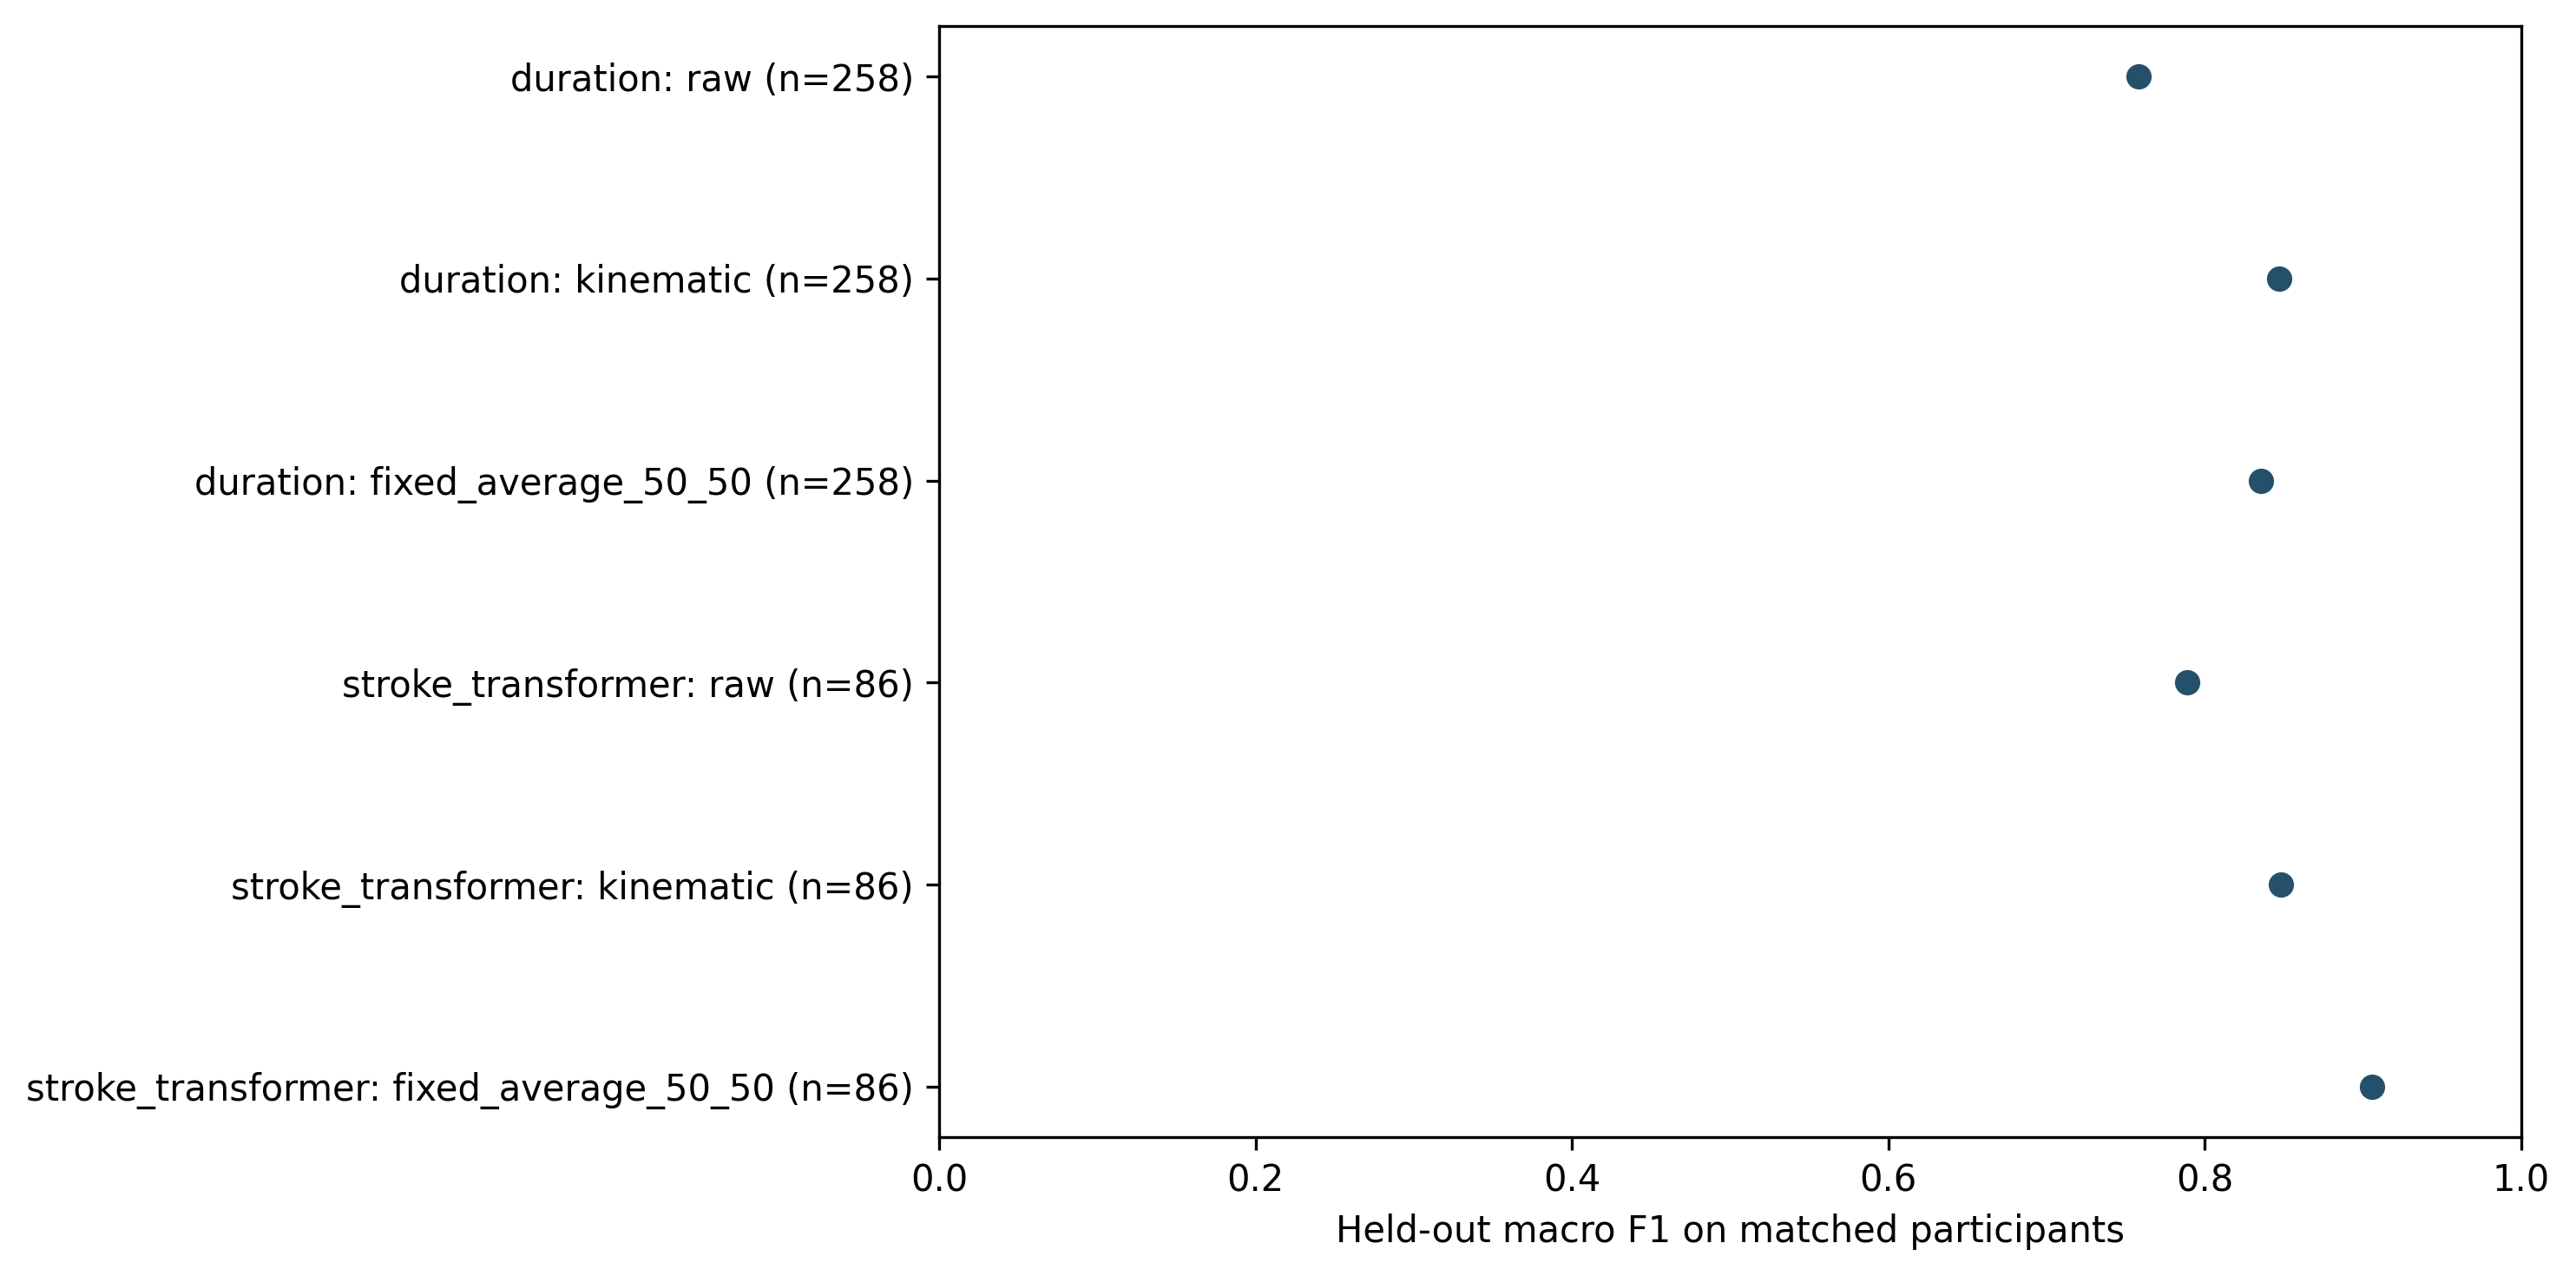

In [5]:
path = LITE / 'figures/paired_f1.png'
if path.exists(): display(Image(filename=str(path)))

## Thời gian, bộ nhớ và checkpoint
Allocated/reserved tensor memory khác với tổng process memory. Không retrain khi mở notebook.

In [6]:
table('runtime_memory.csv')
table('validation_checks.csv')

,model,fold,training_seconds,evaluation_and_replay_seconds,peak_gpu_allocated_mib,peak_gpu_reserved_mib,parameters,epochs
0,duration,0,184.316094,4.894728,390.499023,1308.0,29810,22
1,duration,1,184.132416,1.274411,349.825684,1132.0,29810,22
2,duration,2,179.703258,1.297646,385.078613,1436.0,29810,22
3,duration,3,185.382258,1.227516,383.032227,1068.0,29810,22
4,duration,4,191.243454,2.733921,407.213379,1134.0,29810,22
5,duration,5,204.497132,1.188406,409.871582,1302.0,29810,22
6,stroke_transformer,0,1427.920948,6.298296,289.238770,930.0,25252,28
7,stroke_transformer,1,1477.045752,5.906758,273.410645,842.0,25252,28


,model,fold,participants,checkpoint_replay_error,fit_test_disjoint,normalizer_train_only,outer_test_not_used_for_selection
0,duration,0,43,0.0,True,True,True
1,duration,1,43,0.0,True,True,True
2,duration,2,43,0.0,True,True,True
3,duration,3,43,0.0,True,True,True
4,duration,4,43,0.0,True,True,True
5,duration,5,43,0.0,True,True,True
6,stroke_transformer,0,43,0.0,True,True,True
7,stroke_transformer,1,43,0.0,True,True,True


In [7]:
rows = []
for path in sorted((LITE / 'fits').glob('*/status.json')):
    rows.append(dict(fit=path.parent.name, **json.loads(path.read_text(encoding='utf-8'))))
display(pd.DataFrame(rows))
for name in ['PHASE3_RECOVERY_VI.md', 'PHASE4_LITE_REPORT_VI.md']:
    path = OUT / name
    if path.exists(): display(Markdown(path.read_text(encoding='utf-8')))

,fit,status,epochs_completed,checkpoint_sha256,next_group_cursor,fixed_epochs,training_seconds,optimizer_steps,resume_checkpoint,resume_sha256,signature
0,duration_fold0,complete,22,115c28d2f18b5364d579ec05579030382df733e5a80c5a...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,duration_fold1,complete,22,de03705e08dcb411e6bbf03f47d8d7f407a797509d7f2b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,duration_fold2,complete,22,129413295aaa3190fadf0bb94afc243d824d72d8545bb5...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,duration_fold3,complete,22,774b60aeb5467b6461172802ffdea8315ab2fbf48b4788...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,duration_fold4,complete,22,8ab9772d27369165aaee88e09969928d3af650d3d114af...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,duration_fold5,complete,22,8564bfe025df94a3c37f643fd3cd3e12f899d56cc865c8...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,stroke_transformer_fold0,complete,28,f98df36aab6ea1b896c5c0ea9375fb0bb0ac70e952db17...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,stroke_transformer_fold1,complete,28,9592977dfb32dcee18ceb33c91743b626e71cb6e8d2261...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,stroke_transformer_fold2,paused_session_budget,3,NaN,24.0,28.0,151.893559,84.0,data/derived/raw_temporal_v2/phase4_lite/strok...,18ea2db040d958970607504cefa580a0983cc3c4fecf9c...,6733f2a887ed55f6fab42790170bd30d75c7586156ffcf...


# Phase 3 recovery — kiểm tra CUDA và ngân sách

**Phase 3 chưa hoàn tất.** Đã xác minh bản sửa ở commit `05b3e28` trên dữ liệu thật, strict deterministic CUDA. Lỗi trước đây nằm ở backward của nội suy tuyến tính; bản sửa dùng toán tử tuyến tính tương đương bằng GEMM, giữ nguyên vị trí các tâm convolution. Không đổi kiến trúc hoặc mục tiêu SSL.

| encoder | windows | finite_gradients | repeated_gradients_bitwise_equal | repeated_forward_bitwise_equal | loss | gradient_l2 |
| --- | --- | --- | --- | --- | --- | --- |
| original | 64 | True | True | True | 0.430542 | 0.417668 |
| multiscale | 64 | True | True | True | 0.617661 | 0.649381 |

Normalizer chỉ fit 143 development-Train participants; dữ liệu smoke lấy từ development Train, không dùng 43 outer Test0. Hai lần forward/backward với cùng weights/input tạo kết quả bit-for-bit bằng nhau. Đây là kiểm tra vận hành, không đo chất lượng embedding hay chẩn đoán.

## Epoch pilot và ước lượng

| quantity | value |
| --- | --- |
| epochs_completed | 1 |
| optimizer_updates | 1 |
| eligible_windows | 11432 |
| training_seconds | 1.219256 |
| forward_only_seconds | 0.219249 |
| windows_per_second | 9376.209754 |
| peak_gpu_allocated_mib | 205.583496 |
| peak_gpu_reserved_mib | 340.000000 |
| estimated_full_train_epoch_seconds | 20.571212 |
| estimated_validation_forward_seconds | 1.863599 |
| estimated_two_seed_pretraining_upper_seconds | 538.435468 |
| estimated_full_phase3_seconds | 3739.487523 |
| configured_full_phase3_budget_seconds | 1800 |
| full_suite_estimate_within_budget | False |

Epoch nhỏ gồm 8 người được lấy theo quantile số window trong development Train; dùng toàn bộ window pen-down hợp lệ của mỗi người, một optimizer update với gradient cân bằng theo participant. Normalizer dùng pool 143 Train. Window pen-up không có reconstruction objective vẫn nằm trong dữ liệu classification; không loại khỏi pipeline classifier.

Đây là một epoch trên tập con, không phải một epoch đầy đủ trên 143 người. Ước lượng theo tỷ lệ window: train epoch khoảng 20.57s; reconstruction validation forward khoảng 1.86s. Hai pretraining seed × tối đa 8 epochs, cộng safety factor 1,5, khoảng 8.97 phút. Validation được benchmark forward-only nên chưa bao gồm toàn bộ baseline/masking/ghi file; không coi đây là thời gian cam kết.

Toàn bộ Phase 3 còn gồm 12 neural downstream fits và 38 CPU readout fits. Dùng thời gian downstream duration-aware đã đo để proxy, tổng khoảng 62.32 phút; chưa cộng đủ CPU/extraction và uncertainty. Ngân sách riêng đặt cho full Phase 3 là 30 phút để dành phần còn lại của phiên cho validation nhẹ. Không khởi chạy full SSL. Trạng thái giữ **pilot-only/incomplete**, dù pretraining riêng lẻ có thể khả thi.

Checkpoint pilot: `data/derived/raw_temporal_v2/phase3_recovery/pilot_epoch1.pt` (cache cục bộ), SHA `4f519305e644ca512b843e37cc66c84099737f5c201aabc42f913b0fcc70fb7a`. Không dùng checkpoint này để tạo embedding toàn cohort hoặc đưa vào CV. Chuẩn hóa/encoder đã thấy pool 143 người nên không được tái sử dụng tùy tiện cho các fold khác.


Khuyến nghị: ưu tiên OOF của mô hình scratch đã có tín hiệu development trước. Chỉ lên lịch full SSL sau khi thấy nhu cầu bổ sung thông tin và khóa ngân sách cho cả matched scratch/random/frozen/fine-tune controls; reconstruction loss đơn lẻ không đủ để khẳng định embedding hữu ích.


# Phase 4 lite — đánh giá cấu hình cố định trong ngân sách

**Trạng thái:** `lite_incomplete_resumable`. Primary duration-aware: **6/6 folds**; Stroke Transformer: **2/6 folds**. Phase 3 full SSL và nghiên cứu đầy đủ **chưa hoàn tất**. Protocol Phase 4 đầy đủ được giữ nguyên và không khởi chạy.

## Protocol khóa trước outer evaluation

258 participants, nhãn `group`, original participant-independent Stratified 6-Fold seed42. Một initialization seed42, không inner architecture search. Primary là duration-aware, chọn bằng kết quả development Phase1/2 đã có; secondary là Stroke Transformer. Mỗi mô hình fit mới trên outer Train215, normalizer chỉ fit Train. Primary **22 epochs**, secondary **28 epochs**, lấy rounded median BCE-best development epochs ở hai seed. AdamW LR0.001, weight decay0.001, dropout0.1, clip1, effective batch8/micro2. Không dùng outer Test để early-stop, chọn mô hình, epoch, threshold hoặc fusion weight. Không kéo dài fit dựa vào outer score.

Cả hai mô hình khởi tạo ngẫu nhiên với seed42 và học supervised từ đầu; không dùng checkpoint SSL pilot trong OOF.

Đây là **exploratory internal CV**: cùng cohort đã được xem trong lịch sử và development toàn cục ảnh hưởng cấu hình; không mô tả đây là Nested CV hoặc xác nhận độc lập.

## So sánh OOF trên đúng cùng participants

| candidate | method | participants | completed_folds | all_six_folds_complete | accuracy | f1_macro | auc | balanced_accuracy | specificity |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| duration | raw | 258 | 6 | True | 0.759690 | 0.757930 | 0.822986 | 0.759380 | 0.756522 |
| duration | kinematic | 258 | 6 | True | 0.848837 | 0.847163 | 0.906902 | 0.847461 | 0.834783 |
| duration | fixed_average_50_50 | 258 | 6 | True | 0.837209 | 0.835539 | 0.899240 | 0.836120 | 0.826087 |
| stroke_transformer | raw | 86 | 2 | False | 0.790698 | 0.788871 | 0.881069 | 0.788871 | 0.769231 |
| stroke_transformer | kinematic | 86 | 2 | False | 0.848837 | 0.847829 | 0.933988 | 0.848609 | 0.846154 |
| stroke_transformer | fixed_average_50_50 | 86 | 2 | False | 0.906977 | 0.905702 | 0.956356 | 0.903983 | 0.871795 |

![Matched held-out macro F1](phase4_lite/figures/paired_f1.png)

Mỗi dòng Kinematic được giới hạn đúng IDs/folds có Raw hoàn tất của candidate đó. Chỉ khi 6/6 folds và258 IDs mới gọi là full-cohort OOF. Fold còn thiếu không được điền0 hoặc suy diễn. Mean/sampleSD theo folds ở `paired_comparison.csv`; với một fold, SD chưa xác định. Threshold cố định probability>0.5.

OOF AUC tính trên pooled probabilities; có thể khác mean fold AUC khi thứ hạng/calibration thay đổi giữa các mô hình fold.

## Error overlap và probability average

| candidate | participants | both_correct | kin_only | raw_only | both_wrong | probability_correlation |
| --- | --- | --- | --- | --- | --- | --- |
| duration | 258 | 179 | 40 | 17 | 22 | 0.627886 |
| stroke_transformer | 86 | 57 | 16 | 11 | 2 | 0.555547 |

`raw_only` là trường hợp Raw đúng/Kinematic sai; `kin_only` là Raw sai/Kinematic đúng. Không coi corrected cases riêng lẻ là bằng chứng complementary value. Fusion duy nhất là xác suất **0.5 Kinematic +0.5 Raw**, đã định trước; không fit weights, gate hoặc stacking trên outer predictions. Tất cả probability mức participant ở `phase4_lite/oof_predictions.csv`.

| candidate | method | reference | metric | participants | delta | lower95 | upper95 | bootstrap_replicates |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| duration | raw | kinematic_same_participants | f1_macro | 258 | -0.089234 | -0.145229 | -0.035529 | 500 |
| duration | raw | kinematic_same_participants | auc | 258 | -0.083916 | -0.128884 | -0.037583 | 500 |
| duration | fixed_average_50_50 | kinematic_same_participants | f1_macro | 258 | -0.011624 | -0.048900 | 0.027162 | 500 |
| duration | fixed_average_50_50 | kinematic_same_participants | auc | 258 | -0.007662 | -0.028089 | 0.013741 | 500 |
| stroke_transformer | raw | kinematic_same_participants | f1_macro | 86 | -0.058958 | -0.168935 | 0.064246 | 500 |
| stroke_transformer | raw | kinematic_same_participants | auc | 86 | -0.052919 | -0.135654 | 0.023120 | 500 |
| stroke_transformer | fixed_average_50_50 | kinematic_same_participants | f1_macro | 86 | 0.057873 | -0.013196 | 0.139756 | 500 |
| stroke_transformer | fixed_average_50_50 | kinematic_same_participants | auc | 86 | 0.022368 | -0.012230 | 0.063798 | 500 |

Paired bootstrap500 lần dùng chung participant resamples; trained models cố định, không tính uncertainty do refit/adaptive development. CI trên partial coverage chỉ áp dụng nhóm held-out đã hoàn tất. Không dùng kết quả này để chọn lại training recipe.

## Thời gian, bộ nhớ và resume

| candidate | training_seconds | estimated_outer_train_epoch_seconds | estimated_fold_seconds_with_safety | estimated_six_folds_seconds_with_safety |
| --- | --- | --- | --- | --- |
| duration | 1.119184 | 28.544093 | 942.859735 | 5657.158411 |
| stroke_transformer | 1.493829 | 38.099179 | 1603.459196 | 9620.755174 |

| model | fold | training_seconds | evaluation_and_replay_seconds | peak_gpu_allocated_mib | peak_gpu_reserved_mib | parameters | epochs |
| --- | --- | --- | --- | --- | --- | --- | --- |
| duration | 0 | 184.316094 | 4.894728 | 390.499023 | 1308.000000 | 29810 | 22 |
| duration | 1 | 184.132416 | 1.274411 | 349.825684 | 1132.000000 | 29810 | 22 |
| duration | 2 | 179.703258 | 1.297646 | 385.078613 | 1436.000000 | 29810 | 22 |
| duration | 3 | 185.382258 | 1.227516 | 383.032227 | 1068.000000 | 29810 | 22 |
| duration | 4 | 191.243454 | 2.733921 | 407.213379 | 1134.000000 | 29810 | 22 |
| duration | 5 | 204.497132 | 1.188406 | 409.871582 | 1302.000000 | 29810 | 22 |
| stroke_transformer | 0 | 1427.920948 | 6.298296 | 289.238770 | 930.000000 | 25252 | 28 |
| stroke_transformer | 1 | 1477.045752 | 5.906758 | 273.410645 | 842.000000 | 25252 | 28 |

Chi phí các fit chưa có OOF được ghi riêng, không bỏ khỏi accounting và không điền metrics giả:

| fit | epochs_completed | fixed_epochs | next_group_cursor | optimizer_steps | training_seconds | peak_gpu_allocated_mib | peak_gpu_reserved_mib | oof_available | resumable_checkpoint |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| stroke_transformer_fold2 | 3 | 28 | 24 | 84 | 151.893559 | 272.011230 | 796.000000 | False | data/derived/raw_temporal_v2/phase4_lite/stroke_transformer_fold2.resume.pt |

Ước lượng cập nhật từ các fold thực sự đã hoàn tất (không dùng outer scores để đổi recipe):

| candidate | measured_completed_folds | actual_completed_training_and_replay_seconds | mean_actual_fold_seconds | estimated_remaining_full_folds_seconds | note |
| --- | --- | --- | --- | --- | --- |
| duration | 6 | 1141.891240 | 190.315207 | 0.000000 | Runtime extrapolation only, does not change architecture/epochs; unfinished-fold work not subtracted |
| stroke_transformer | 2 | 2917.171753 | 1458.585876 | 5834.343506 | Runtime extrapolation only, does not change architecture/epochs; unfinished-fold work not subtracted |

Benchmark dùng tám development-Train people, đầy đủ recordings; dự báo theo window count, scaling tới215 Train, safety factor1.5. Chi phí lịch sử Phase2 giữ riêng, không nhầm với thời gian đo mới. `training_seconds` gồm lưu resume checkpoint mỗi optimizer update; `evaluation_and_replay_seconds` gồm outer inference và replay checkpoint. Tensor allocated/reserved peak khác với tổng process memory trong nvidia-smi. Pilot benchmarks không phải outer fits.

Dự báo nhỏ có thể lệch vì warm-up, cache và kích thước các bag; thời gian actual của fold và session là số dùng cho accounting. Bảng forecast không phải thời gian đã tiêu tốn.

Mỗi phiên tối đa120 phút; mặc định110, có reserve cho ghi file/report. Checkpoint gồm weights, optimizer, CPU/CUDA/Python/NumPy RNG, permutation và cursor. Ngắt ở ranh giới optimizer update, tiếp tục đúng phần còn lại. Mọi epoch giữ toàn bộ cached samples, không silently truncate. Các phiên trong `phase4_lite/sessions/`; các fold dở trong `fits/*/status.json`.

| session | status | maximum_seconds | elapsed_seconds | reporting_seconds |
| --- | --- | --- | --- | --- |
| 20261118_160018_4d0d94 | failed | 4500.000000 | 831.027483 |  |
| 20261118_161641_70c92b | paused_session_budget | 3516.521572 | 3431.606928 | 38.901688 |

Log lỗi I/O của lần chạy đầu được giữ trong `session_current.stderr.log` và `io_failure_recovery.json`. Checkpoint trước lỗi được resume với cùng training signature; retry chỉ thay thao tác ghi file. Thời hạn kết thúc ban đầu giữ nguyên. Cumulative fit timers lấy từ checkpoint; tổng thời gian session cũng bao gồm công việc dở trước lỗi và startup. Hai loại thời gian không được cộng lặp.

Tiếp tục trong phiên khác: `.venv/Scripts/python.exe scripts/session_raw_temporal_v2_lite.py --minutes 110`. Wrapper bổ sung retry cho atomic checkpoint replace khi Windows tạm khóa file; code toán học và training signature được giữ nguyên. Không tự tạo phiên thứ hai sau khi chạm budget. Nếu có phục hồi do lỗi I/O, thời hạn kết thúc ban đầu vẫn được giữ bằng `--deadline-unix`.

## Khuyến nghị nghiên cứu

Duration-aware trên 258 người hiện có ΔF1 Raw−Kinematic=-0.089234, average−Kinematic=-0.011624. Average chưa có CI F1 hoàn toàn dương so với Kinematic. Chưa có bằng chứng đủ mạnh để ưu tiên full nested fusion/SSL; giữ baseline và hoàn tất đối chứng cố định còn thiếu trước. Stroke Transformer average trên 86 người hiện có ΔF1=+0.057873, CI95% [-0.013196,+0.139756]. Đây mới là partial OOF; nếu có tín hiệu thuận lợi thì bước hợp lý là hoàn tất 4 folds còn thiếu theo protocol đã định trước trong các phiên ngắn, không chọn kiến trúc hoặc trọng số mới từ các outer scores này.

Ưu tiên hoàn tất các folds của protocol lite đã khóa trước khi chi thêm cho nested search hoặc kiến trúc mới. Nếu Raw hoặc fixed-average không chứng minh lợi ích trên tập OOF đã hoàn tất, chưa có cơ sở chi ngân sách cho full nested fusion. Chỉ cân nhắc nested CV sau một tín hiệu ổn định cần kiểm chứng bằng Train-only selection và một ngân sách mới. SSL recovery mới là pilot; chưa có downstream comparison để khuyến nghị full SSL. Không mở thêm architecture grid từ kết quả outer folds hiện tại.

Bảo toàn artifacts cũ: đã kiểm tra 2516 paths và 1921 protected references bằng SHA. Baseline Kinematic OOF được dùng nguyên trạng. Báo cáo/code/results mới nằm riêng; không push hoặc merge tự động.
